# Librerias

In [19]:
import sys
import os

# Agrega la carpeta raíz del proyecto al path de Python
sys.path.append(os.path.abspath(os.path.join('..')))


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nbformat
import openpyxl
from dython.nominal import associations
from scipy.stats import gaussian_kde

from src.Data_Processor import DataProcessor



# Carga de datos

In [20]:
procesador = DataProcessor().load_data('../data/processed/Proyecto_B_Clientes_Limpio.parquet')

Dimenciones del dataset

In [21]:
procesador.data.shape

(7043, 23)

Primeras 60 filas del dataset

In [22]:
procesador.data.head(60)

,Genero,Adulto_Mayor,Pareja,Dependientes,Antiguedad(Meses),Servicio_Telefono,Lineas_Multiples,Internet_DSL,Internet_Fiber optic,Seguridad_Online,...,Streaming_TV,Streaming_Peliculas,Contrato,Facturacion_Electronica,MP_Electronic check,MP_Mailed check,MP_Bank transfer (automatic),Cargos_Mensuales,Cargos_Totales,Abandono
0,Female,0,1,0,1.0,0,0,1,0,0,...,0,0,0,1,1,0,0,29.85,29.85,0
1,Male,0,0,0,34.0,1,0,1,0,1,...,0,0,1,0,0,1,0,56.95,1889.50,0
2,Male,0,0,0,2.0,1,0,1,0,1,...,0,0,0,1,0,1,0,53.85,108.15,1
3,Male,0,0,0,45.0,0,0,1,0,1,...,0,0,1,0,0,0,1,42.30,1840.75,0
4,Female,0,0,0,2.0,1,0,0,1,0,...,0,0,0,1,1,0,0,70.70,151.65,1
5,Female,0,0,0,8.0,1,1,0,1,0,...,1,1,0,1,1,0,0,99.65,820.50,1
6,Male,0,0,1,22.0,1,1,0,1,0,...,1,0,0,1,0,0,0,89.10,1949.40,0
7,Female,0,0,0,10.0,0,0,1,0,1,...,0,0,0,0,0,1,0,29.75,301.90,0
8,Female,0,1,0,28.0,1,1,0,1,0,...,1,1,0,1,1,0,0,104.80,3046.05,1
9,Male,0,0,1,62.0,1,0,1,0,1,...,0,0,1,0,0,0,1,56.15,3487.95,0


Informacion sobre el dataset

In [23]:
procesador.data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column                        Non-Null Count  Dtype   
---  ------                        --------------  -----   
 0   Genero                        7043 non-null   category
 1   Adulto_Mayor                  7043 non-null   int64   
 2   Pareja                        7043 non-null   int64   
 3   Dependientes                  7043 non-null   int64   
 4   Antiguedad(Meses)             7043 non-null   float64 
 5   Servicio_Telefono             7043 non-null   int64   
 6   Lineas_Multiples              7043 non-null   int64   
 7   Internet_DSL                  7043 non-null   int8    
 8   Internet_Fiber optic          7043 non-null   int8    
 9   Seguridad_Online              7043 non-null   int64   
 10  Copia_Seguridad_Online        7043 non-null   int64   
 11  Proteccion_Dispositivos       7043 non-null   int64   
 12  Soporte_Tecnico               7043 non-null   int64   
 13 

Verificacion de nulos

In [24]:
procesador.data.isnull().sum()

Genero                          0
Adulto_Mayor                    0
Pareja                          0
Dependientes                    0
Antiguedad(Meses)               0
Servicio_Telefono               0
Lineas_Multiples                0
Internet_DSL                    0
Internet_Fiber optic            0
Seguridad_Online                0
Copia_Seguridad_Online          0
Proteccion_Dispositivos         0
Soporte_Tecnico                 0
Streaming_TV                    0
Streaming_Peliculas             0
Contrato                        0
Facturacion_Electronica         0
MP_Electronic check             0
MP_Mailed check                 0
MP_Bank transfer (automatic)    0
Cargos_Mensuales                0
Cargos_Totales                  0
Abandono                        0
dtype: int64

In [25]:
procesador.data.isna().sum()

Genero                          0
Adulto_Mayor                    0
Pareja                          0
Dependientes                    0
Antiguedad(Meses)               0
Servicio_Telefono               0
Lineas_Multiples                0
Internet_DSL                    0
Internet_Fiber optic            0
Seguridad_Online                0
Copia_Seguridad_Online          0
Proteccion_Dispositivos         0
Soporte_Tecnico                 0
Streaming_TV                    0
Streaming_Peliculas             0
Contrato                        0
Facturacion_Electronica         0
MP_Electronic check             0
MP_Mailed check                 0
MP_Bank transfer (automatic)    0
Cargos_Mensuales                0
Cargos_Totales                  0
Abandono                        0
dtype: int64

Cantidad de valores unicos por variable

In [26]:
procesador.data.nunique()

Genero                             2
Adulto_Mayor                       2
Pareja                             2
Dependientes                       2
Antiguedad(Meses)                 73
Servicio_Telefono                  2
Lineas_Multiples                   2
Internet_DSL                       2
Internet_Fiber optic               2
Seguridad_Online                   2
Copia_Seguridad_Online             2
Proteccion_Dispositivos            2
Soporte_Tecnico                    2
Streaming_TV                       2
Streaming_Peliculas                2
Contrato                           3
Facturacion_Electronica            2
MP_Electronic check                2
MP_Mailed check                    2
MP_Bank transfer (automatic)       2
Cargos_Mensuales                1585
Cargos_Totales                  6531
Abandono                           2
dtype: int64

## Matris de correlaciones

La data contiene pocas variables numericas, por lo que revizar correlaciones con metodos tradicionles como pearson o espearman no es la mejor opcion. Por lo tanto, se utilizara associations de dython para comprobar las correlaciones mixtas del dataset, al tener pocas variables numericas y al no tener variables ordinales, los valores de las correlaciones solo indicaran la intensidad de la correlacion entre variables

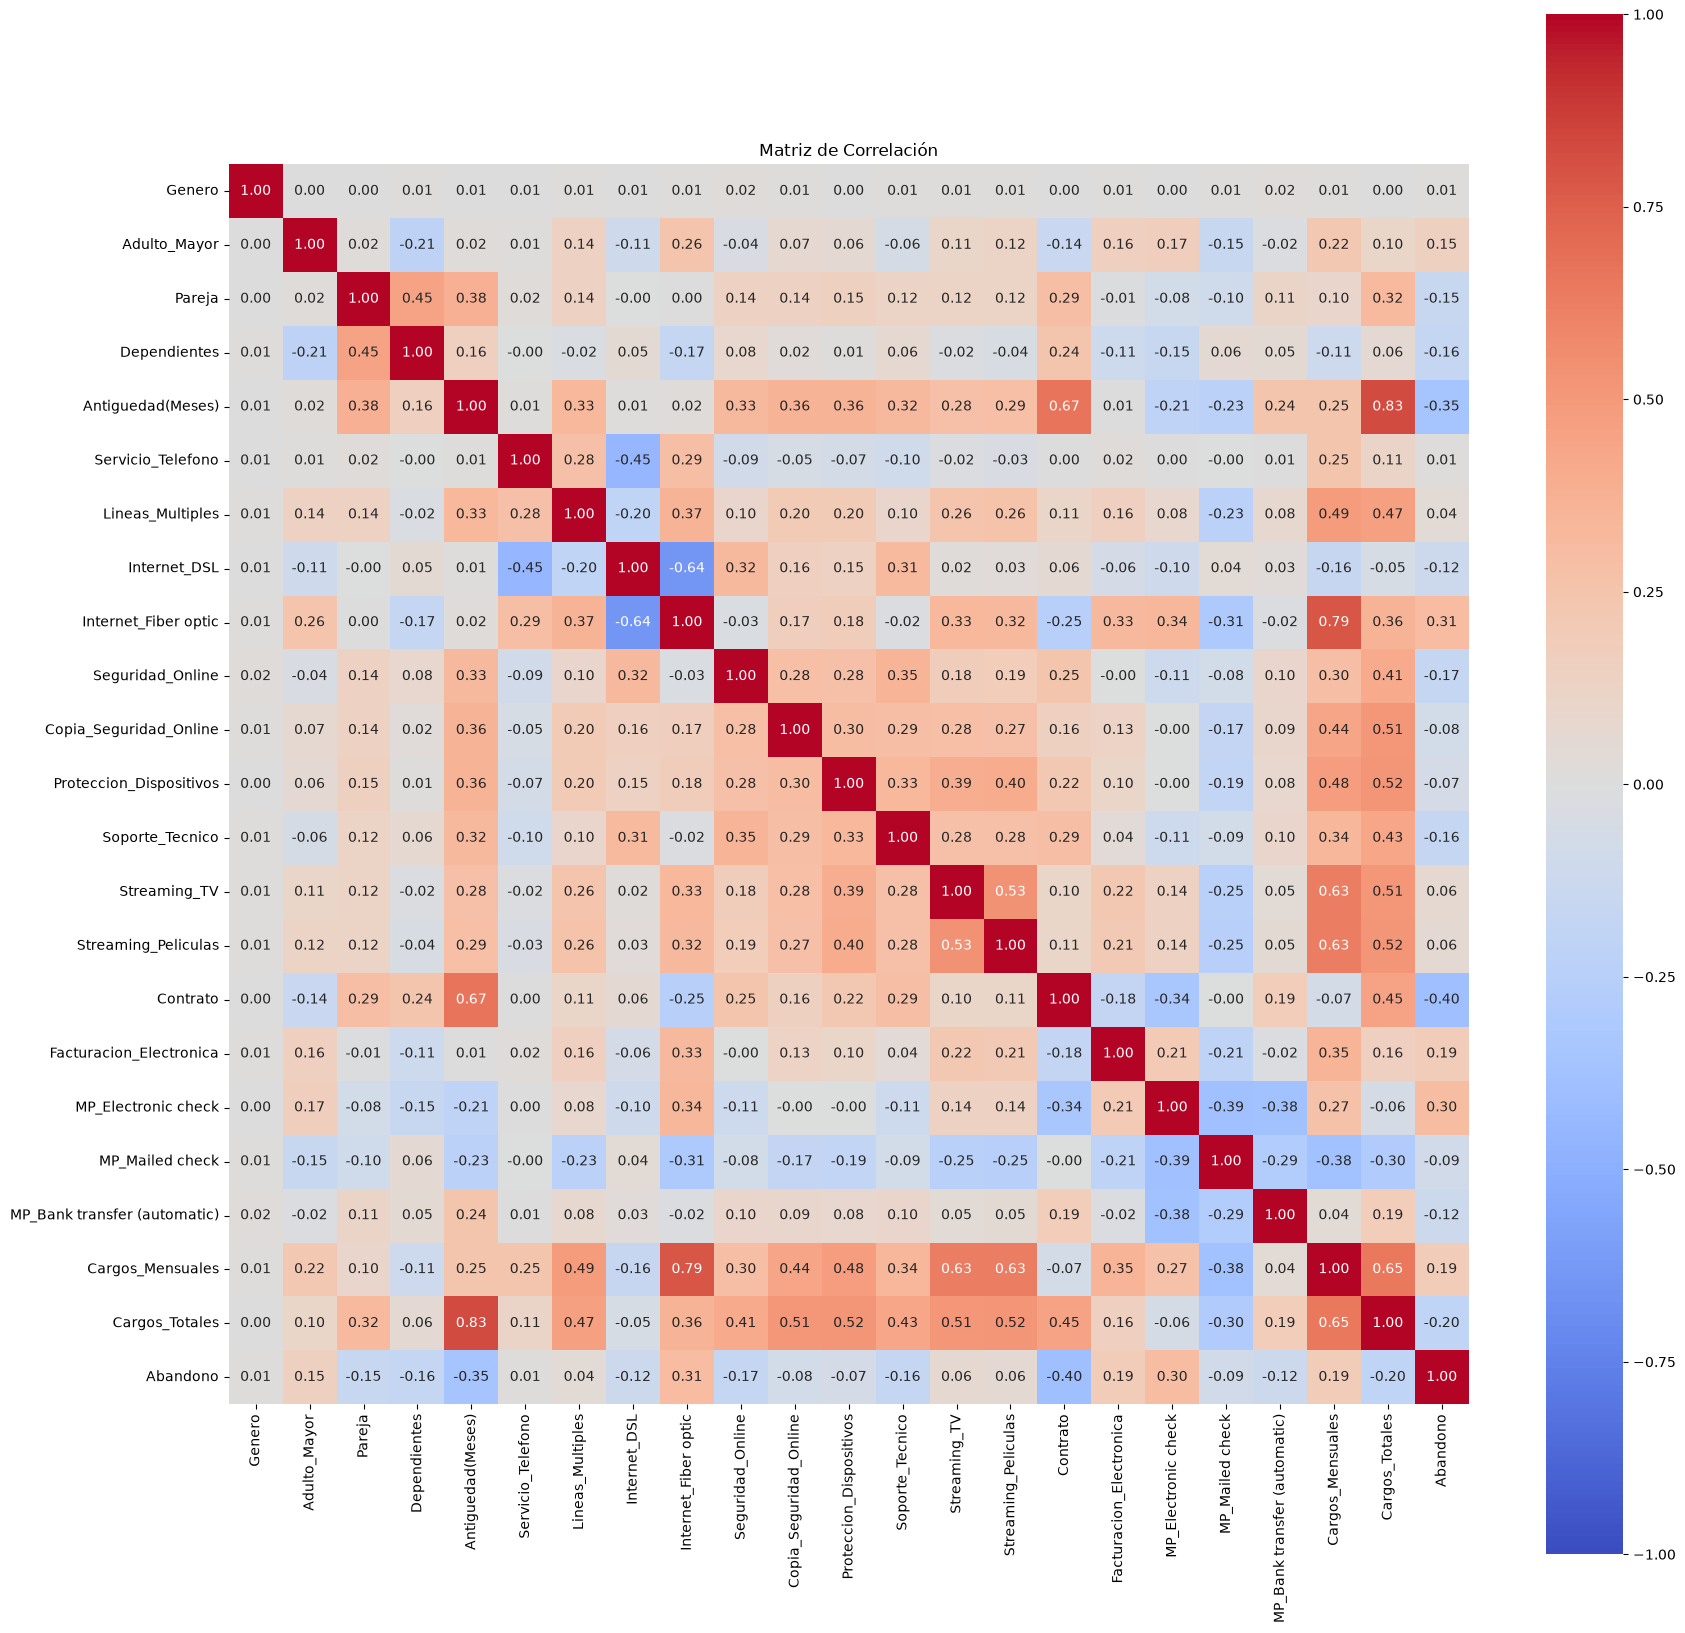

In [27]:
resultados = associations(
    procesador.data, 
    figsize=(20, 20), 
    cmap='coolwarm',
    title='Matriz de Correlación',
    fmt=".2f",
    annot=True
    )


La matris de correlaciones presenta corelacions medias entre la gran mayoria de la data, solo la variable de genero presenta correlaciones practicamente nulas con el resto de variables, el resto de variables si presentan un estructura optima para integrarlas en el entrenamiento del modelo de ANN, los datos nulos dentro de las variables se lograron integrar de manera correcta por lo que no se opta por eliminar ningun dato de momento.

Algunas observaciones sobre la correlaciones:
- Se aprecia una correlacion inversamente proporcional entre el ser adulto mayor y tener dependientes, por lo general un adulto mayor no tiene personas a su cuidado, lo que cuadra con los datos mostrados.
- Se aprecia una correlacion inversa entre la antiguedad y el abandonó, un posible indicador que que a mayor cantidad de meses los abonados pueden retenerse mejor.
- Se aprecia una correlacion inversa de intensidad baja entre abandonar y tener pareja, pudiendo indicar una retencion del servicio por abonado de quienes tienden a tener pareja o sentar cabeza.
- Se presenta una correlacion proporcional entre los abandonos y el internet de fibra optica, pudiendo inferir a partir de esto que los abonados que dimitieron del servicio esten presentando mas fallos en este servicio.
- Se presenta una correlacion inversa entre los contratos y el abandonó, pudiendo indicar la retencion de abonados que estos tienden a preferir contratos de plazos mas largos.
- Se presenta una correlacion proporcional entre la antiguedad y el contrato, pudiendo indicado una posible tendencia de retencion de los abonados al optar por contratos de plazos mas amplios.

La variable de Cargos totales presenta correlaciones altas con la de cargos mensuales y la de antiguedad, al ser una variable derivada de estas es mejor eliminarla para evir redundancios o problemas por multicolinealidad, otra variable que no aporta estadisticamente, y por ello se presindira de la misma para el modelo, es la de genero al no presetar correlaciones con ninguna variable.

In [28]:
procesador.data.drop(["Cargos_Totales", "Genero"], axis=1, inplace=True)

## Medias Estadisticas

In [29]:
procesador.data.drop('Contrato', axis=1).describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Adulto_Mayor,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
Pareja,7043.0,0.483033,0.499748,0.00,0.0,0.00,1.00,1.00
Dependientes,7043.0,0.299588,0.458110,0.00,0.0,0.00,1.00,1.00
Antiguedad(Meses),7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
Servicio_Telefono,7043.0,0.903166,0.295752,0.00,1.0,1.00,1.00,1.00
Lineas_Multiples,7043.0,0.421837,0.493888,0.00,0.0,0.00,1.00,1.00
Internet_DSL,7043.0,0.343746,0.474991,0.00,0.0,0.00,1.00,1.00
Internet_Fiber optic,7043.0,0.439585,0.496372,0.00,0.0,0.00,1.00,1.00
Seguridad_Online,7043.0,0.286668,0.452237,0.00,0.0,0.00,1.00,1.00
Copia_Seguridad_Online,7043.0,0.344881,0.475363,0.00,0.0,0.00,1.00,1.00


### Distribucion de los individuos entre los rangos numericos continuos

In [30]:

def plot_boxplot_histogram(df, column):
    x = df[column].dropna()
    fig, (ax_box, ax_hist) = plt.subplots(2, 1, sharex=True, figsize=(10, 6),
                                        gridspec_kw={"height_ratios": [1, 4]})
    
    plt.subplot(2, 1, 1).set_title(f"Distribución de la variable '{column}'", fontsize=14, fontweight='bold')
    
    ax_box.boxplot(x, widths=0.6, orientation="horizontal")
    ax_box.set_yticks([])

    ax_hist.hist(x, density=True, alpha=0.6, edgecolor="white")
    xs = np.linspace(x.min(), x.max(), 300)
    ax_hist.plot(xs, gaussian_kde(x)(xs), color="darkblue", lw=2, label="Densidad Estimada por núcleo (KDE)")
    ax_hist.legend()
    plt.show()

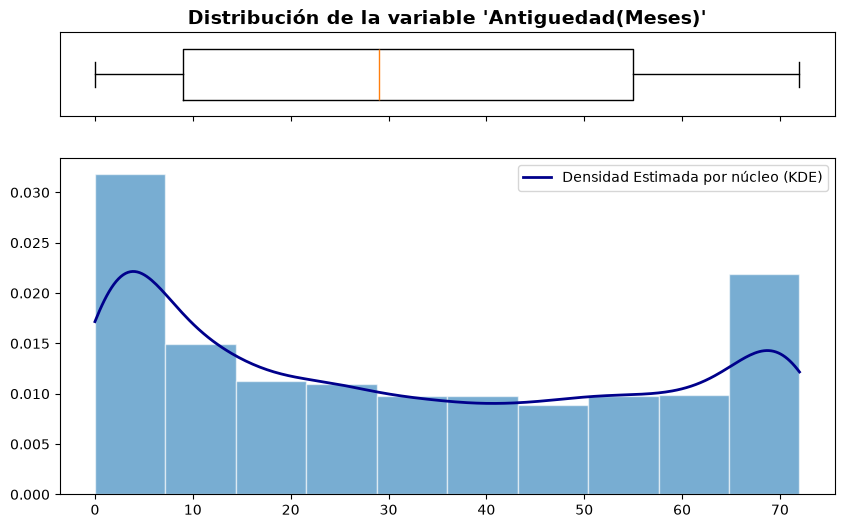

In [31]:
procesador.graficos.plot_boxplot_histogram(procesador.data, "Antiguedad(Meses)")

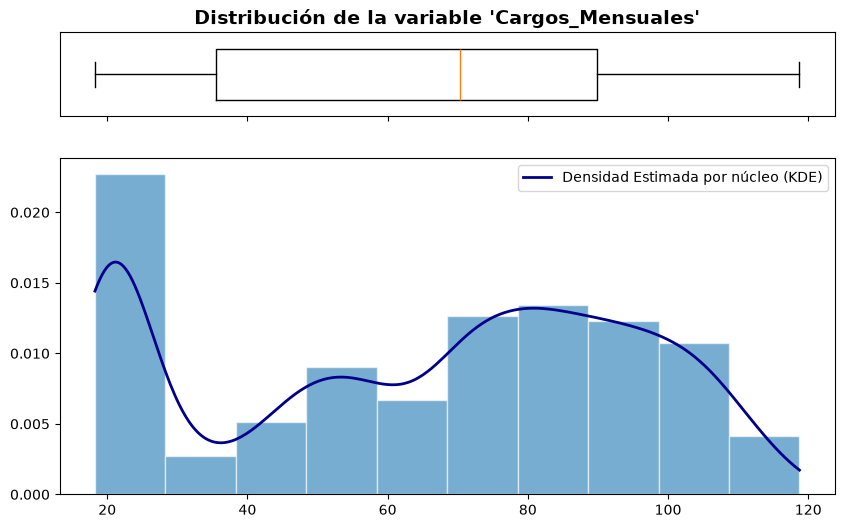

In [32]:
procesador.graficos.plot_boxplot_histogram(procesador.data, "Cargos_Mensuales")

Las distribuciones de los histogramas no presentan una distribucion normal de los datos.

Observaciones sobre las graficas.

Antiguedad(Meses):
- La grafica muetra un agrupamiento de los datos en los extremos de este.
- Presentar datos muy parejos la zona media y un una distribucion un poco pareja de estos.
- El boxplot indica de que los datos se encuentran con cierta uniformidad pero con una amplia distribucion por parte de estos.


Cargos_Mensuales:
- La grafica presenta una densidad alta en los cargos de 20 dolares y un agrupamuento entre los 80 y 100 dolares.
- El boxplot presenta una amplia distribucion de los valores entre el Q1 y la mediana.
- La distribucion de los datos se puede deber a una distribucion un poco pareja entre planes basicos de los clientes nuevos y los que integras servicios adicionales conforme deciden mantener el servicio.

### Distribucion de la variable de salida

('0', '1')


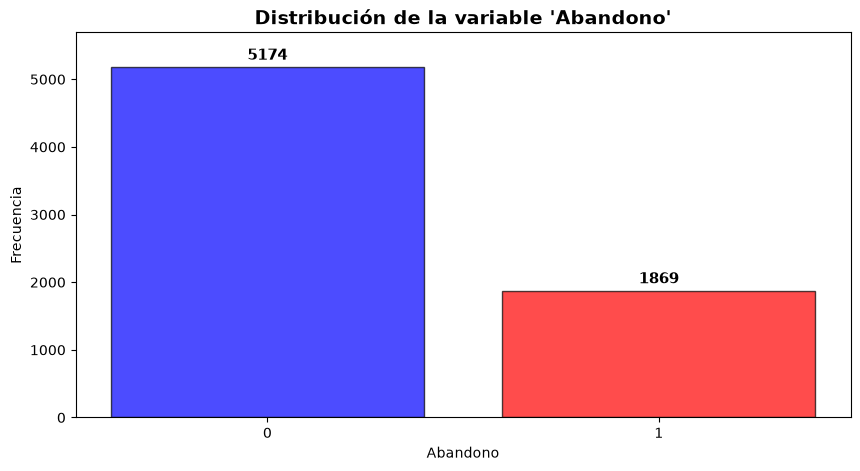

In [33]:
procesador.graficos.plot_bar(procesador.data, "Abandono")

In [34]:
data = procesador.data

In [35]:
print(
    f"Proporción de clientes que abandonaron: {procesador.data.iloc[:, -1].value_counts().get(1, 0) / len(procesador.data):.2%}"
    )
print(
    f"Proporción de clientes que no abandonaron: {procesador.data.iloc[:, -1].value_counts().get(0, 0) / len(procesador.data):.2%}"
    )
print(
    f"Proporción de clientes que abandonaron respecto a los que no abandonaron: {(procesador.data.iloc[:, -1].value_counts().get(1, 0) / len(procesador.data)) / (procesador.data.iloc[:, -1].value_counts().get(0, 0) / len(procesador.data)):.2%}"
    )
print(
    f"Diferencia porcentual entre los clientes que no abandonaron y los que abandonaron: {((procesador.data.iloc[:, -1].value_counts().get(0, 0) / len(procesador.data)) - (procesador.data.iloc[:, -1].value_counts().get(1, 0) / len(procesador.data))) * 100:.2f}%"
    )
print(
    f"Diferencia relativa entre los clientes que no abandonaron y los que abandonaron: {(((procesador.data.iloc[:, -1].value_counts().get(0, 0) / len(procesador.data)) / (procesador.data.iloc[:, -1].value_counts().get(1, 0) / len(procesador.data)) - 1)) * 100:.2f}%"
    )

Proporción de clientes que abandonaron: 26.54%
Proporción de clientes que no abandonaron: 73.46%
Proporción de clientes que abandonaron respecto a los que no abandonaron: 36.12%
Diferencia porcentual entre los clientes que no abandonaron y los que abandonaron: 46.93%
Diferencia relativa entre los clientes que no abandonaron y los que abandonaron: 176.83%


En el grafico se muestra lo desproporcionado que se encuentra el dataset en torno a las variables de salida, por lo que si e dataset se divide sin cuidado las particiones pueden quedar desvalanceadas.

Un 26,54% de los datos corrsponden a un cliente que abandono y el otro 73,46% de los datos corresponde a un cliente que sigue disponiendo del servicio contratado, lo que indica una diferencia porcentual aproximada del 46.92%, lo que equivaldria a una razon de 0.3612 personas que dimiten del servicio por cada cliente retenido, es decir que los clientes que dimitieron del servicio equivaldrian aproximadamente a un 36.12% de los clientes retenidos.

Si interpretamos la diferencia realtiva del porcentaje de cambio respecto al grupo que dimiten, se muestra que el grupo retenido es un 176.83% mayor que los que dimiten, por lo que se refuerza la idea de manejar la particion para entrenamiento y prueba con proporciones equivalentes por cada grupo para evitar subconjuntos desvalanceados.

## Guardado del dataset

In [36]:
# Mantiene los booleanos y categorías exactamente como se configuraron
procesador.save_data('../data/processed/Proyecto_B_Clientes_Limpio.parquet', index=False)

# Concluciones


El dataset se encuentra bastante integro, tras el EDA se identifican las variables necesarias para integrar en el modelo ANN, dejando solo de lado dos variables de este, "Genero" y "Cargo_Total" para evitar generar ruido en el modelo con variables redundantes y sin peso sobre los patrones del conjunto de datos.

La variables numericas presentan una particion al tender a los extremos de sus escalas, por un lado ven clientes nuevos que apenas tienen al menos un mes y otros que tienen almenos 5 años, ademas de encajar un poco con la distribucion de los cargos mensuales, presentado valores en torno a los 20 dolares que serian servicos basicos y valores un poco mas distribudos hacia la cola derecha del grafico, distribuyendo los clientes restantes entre los que agregan mas servicios a sus contratos desde un inicio o conforme va pasando el tiempo y deciden agregar mas servicios o prestaciones al contrato.

La variable de salida presenta una proporcion aproximada de 3 a 1 por lo que en la fase de particion se deben de distribuir los datos de forma tal que se saquen los suficientes casos en los que se indique el abandono del servicio para evitar que el modelo se ajuste demaciado a los datos de clientes retenidos y con ello que se generen prediciones errorneas, los lo que se recomienda dividir los datos en conjuntos por cada grupo segun el abandono del servicio para sacar proporciones equivalentes por cada grupo, es decir extraer el 80% de cada grupo y juntarlos para mantener una particion de entrenamiento equivalente en proporcion a las cantidades de cada uno.